# Import data Files

In [ ]:
import pandas as pd
import numpy as np
# transaction file
df = pd.read_csv("../data/transactions_train.csv")
df.head()

,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2


In [ ]:
# Customer, Articles and Sample Submissions
df_customers = pd.read_csv("../data/customers.csv")
df_articles = pd.read_csv("../data/articles.csv")
df_sample_subs = pd.read_csv("../data/sample_submission.csv")

## Merging Article and customer data

In [9]:
df1 = pd.merge(df,df_customers,on = 'customer_id',how = 'left')
df2 = pd.merge(df1,df_articles,on = 'article_id',how = 'left')
df2.head()

,t_dat,customer_id,article_id,price,sales_channel_id,FN,Active,club_member_status,fashion_news_frequency,age,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2,NaN,NaN,ACTIVE,NONE,24.0,...,Expressive Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Lace push-up body with underwired, moulded, pa..."
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2,NaN,NaN,ACTIVE,NONE,24.0,...,Casual Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Lace push-up bras with underwired, moulded, pa..."
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2,1.0,1.0,ACTIVE,Regularly,32.0,...,Tops Knitwear DS,D,Divided,2,Divided,58,Divided Selected,1003,Knitwear,Jumper in rib-knit cotton with hard-worn detai...
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2,1.0,1.0,ACTIVE,Regularly,32.0,...,Campaigns,A,Ladieswear,1,Ladieswear,15,Womens Everyday Collection,1023,Special Offers,V-neck knitted jumper with long sleeves and ri...
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2,1.0,1.0,ACTIVE,Regularly,32.0,...,Campaigns,A,Ladieswear,1,Ladieswear,15,Womens Everyday Collection,1023,Special Offers,V-neck knitted jumper with long sleeves and ri...


In [ ]:
# Checking duplicates post join
print(df.shape)
print(df2.shape)

(31788324, 5)
(31788324, 35)


## EDA on Customers and Articles

In [20]:
print(f"unique customers:{df_customers.customer_id.nunique()}")
print(f"acitive/incative:{df_customers.club_member_status.value_counts()}")
print(f"transactions unique customers:{df2.customer_id.nunique()}")


unique customers:1371980
acitive/incative:club_member_status
ACTIVE        1272491
PRE-CREATE      92960
LEFT CLUB         467
Name: count, dtype: int64
transactions unique customers:1362281


## insights
1) Not all customers made purchases
2) Not all customers are active
3) Need to check how these 3 categories in club member status have sales transactions
4) Predictions are to be made on next 7 days of max date
5) Check for customer activity and recency from the cut off date
6) Check per status which customers are making purchases and whats the recency
7) Check per sales channel, per fashion news frequency, per age bracket insights on purchases per time period

In [25]:
df2.columns
df2['t_dat'] = pd.to_datetime(df2['t_dat'])
df2.dtypes

t_dat                           datetime64[ns]
customer_id                             object
article_id                               int64
price                                  float64
sales_channel_id                         int64
FN                                     float64
Active                                 float64
club_member_status                      object
fashion_news_frequency                  object
age                                    float64
postal_code                             object
product_code                             int64
prod_name                               object
product_type_no                          int64
product_type_name                       object
product_group_name                      object
graphical_appearance_no                  int64
graphical_appearance_name               object
colour_group_code                        int64
colour_group_name                       object
perceived_colour_value_id                int64
perceived_col

### Define buckets for recency in sales
1) check percentiles
2) set thresholds 

In [39]:
df_time = df2.groupby(['customer_id']).agg({'t_dat':'max'}).reset_index()
df_time['latest_sale_to_cut_off_date'] = df2['t_dat'].max() - df_time['t_dat']
df_time.head()

,customer_id,t_dat,latest_sale_to_cut_off_date
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,2020-09-05,17 days
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,2020-07-08,76 days
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,2020-09-15,7 days
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,2019-06-09,471 days
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,2020-08-12,41 days


In [40]:
## Creating percentiles
percentiles = np.arange(1,101,1)
raw_timedelta = np.percentile(df_time['latest_sale_to_cut_off_date'],percentiles)
values_in_days = raw_timedelta / np.timedelta64(1, 'D')
values_in_days[:5]


array([1., 2., 4., 5., 6.])

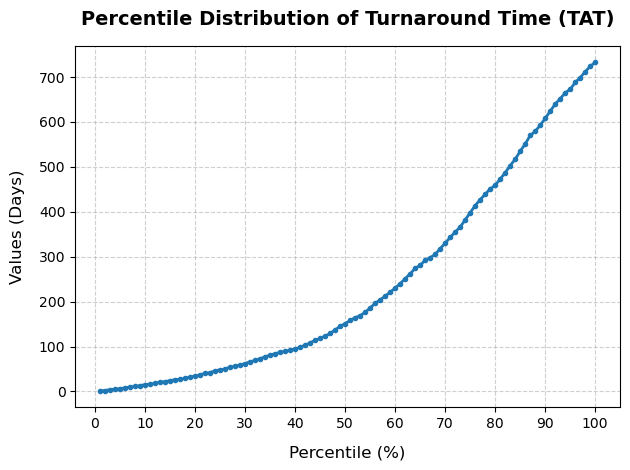

In [41]:
import matplotlib.pyplot as plt
plt.plot(percentiles, values_in_days, marker='.', linestyle='-', color='#1f77b4', linewidth=2)

# Formatting axes, gridlines, and clear labels
plt.title('Percentile Distribution of Turnaround Time (TAT)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Percentile (%)', fontsize=12, labelpad=10)
plt.ylabel('Values (Days)', fontsize=12, labelpad=10)
plt.xticks(np.arange(0, 101, 10))  # Clean markers every 10%
plt.grid(True, linestyle='--', alpha=0.6)

# Prevent axis labels from getting truncated
plt.tight_layout()

# Save the visualization directly
plt.savefig('percentile_distribution_chart.png', dpi=300)

In [42]:
df_time['bucket'] = pd.qcut(df_time['latest_sale_to_cut_off_date'],
                            q = [0,0.25,0.5,0.75,1.0],
                            labels = ['1-25 percentile (50d)', '25-50 (150d)', '50-75 (400d)', '75-100 (740d)'])
df_time = df_time[['customer_id','latest_sale_to_cut_off_date','bucket']]
df_time.head()

,customer_id,latest_sale_to_cut_off_date,bucket
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,17 days,1-25 percentile (50d)
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,76 days,25-50 (150d)
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,7 days,1-25 percentile (50d)
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,471 days,75-100 (740d)
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,41 days,1-25 percentile (50d)


In [43]:
df3 = pd.merge(df2,df_time, on = ['customer_id'],how = 'left')
df3.head()

,t_dat,customer_id,article_id,price,sales_channel_id,FN,Active,club_member_status,fashion_news_frequency,age,...,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc,latest_sale_to_cut_off_date,bucket
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2,NaN,NaN,ACTIVE,NONE,24.0,...,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Lace push-up body with underwired, moulded, pa...",7 days,1-25 percentile (50d)
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2,NaN,NaN,ACTIVE,NONE,24.0,...,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Lace push-up bras with underwired, moulded, pa...",7 days,1-25 percentile (50d)
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2,1.0,1.0,ACTIVE,Regularly,32.0,...,Divided,2,Divided,58,Divided Selected,1003,Knitwear,Jumper in rib-knit cotton with hard-worn detai...,132 days,25-50 (150d)
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2,1.0,1.0,ACTIVE,Regularly,32.0,...,Ladieswear,1,Ladieswear,15,Womens Everyday Collection,1023,Special Offers,V-neck knitted jumper with long sleeves and ri...,132 days,25-50 (150d)
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2,1.0,1.0,ACTIVE,Regularly,32.0,...,Ladieswear,1,Ladieswear,15,Womens Everyday Collection,1023,Special Offers,V-neck knitted jumper with long sleeves and ri...,132 days,25-50 (150d)


/var/folders/0q/h_h23__s6kzbxw_96cqr6mw40000gn/T/ipykernel_8723/426021426.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_bucket_sales = df3.groupby(['bucket']).agg({'article_id':'count','price':'sum'}).reset_index()


                  bucket  article_id          price  volume_contribution  \
0  1-25 percentile (50d)    16827830  474955.333407             0.529371   
1           25-50 (150d)     8571700  232242.777695             0.269649   
2           50-75 (400d)     4300721  122112.325169             0.135292   
3          75-100 (740d)     2088073   55335.537780             0.065687   

   price_contribution  
0            0.536887  
1            0.262526  
2            0.138035  
3            0.062551  


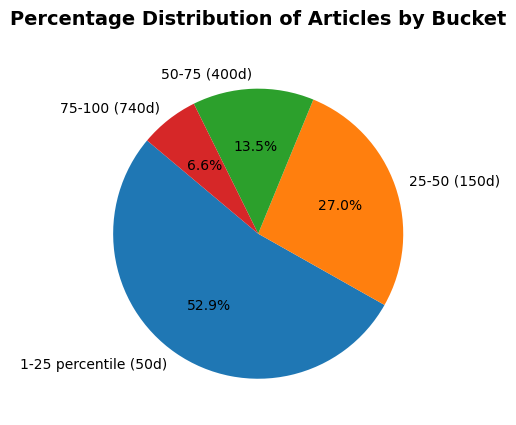

In [50]:
df_bucket_sales = df3.groupby(['bucket']).agg({'article_id':'count','price':'sum'}).reset_index()
df_bucket_sales['volume_contribution'] = df_bucket_sales['article_id']/df_bucket_sales.article_id.sum()
df_bucket_sales['price_contribution'] = df_bucket_sales['price']/df_bucket_sales.price.sum()
print(df_bucket_sales)
plt.figure(figsize= (5,5))
plt.pie(df_bucket_sales['article_id'],
        labels = df_bucket_sales['bucket'],
        autopct='%1.1f%%',          # Shows the percentage numbers on the slices
        startangle=140,             # Rotates the start for a cleaner look
        colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']) # Clean corporate colors

plt.title('Percentage Distribution of Articles by Bucket', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# insight
1) Customers that had sales in last 50d of max date contribute to 52% sales (top 25 percentile)
2) As the percentile value increases, i.e. customers that had sales far back in time, their contribution is also lower (expected)

In [64]:
na = df_customers[~(df_customers['age'].isna())]
na.head()

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


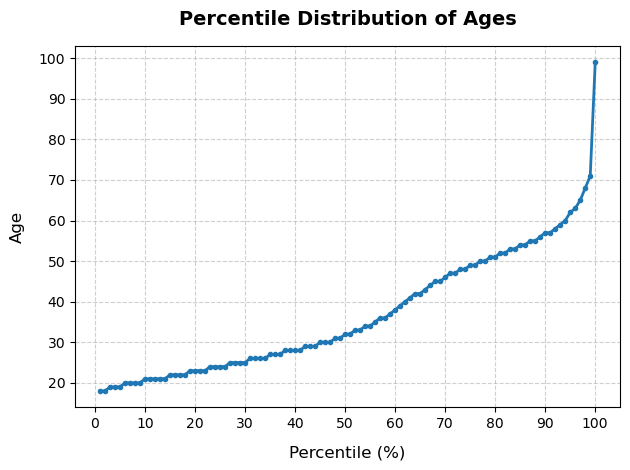

In [65]:
ages = np.percentile(na['age'],percentiles)
plt.plot(percentiles, ages, marker='.', linestyle='-', color='#1f77b4', linewidth=2)

# Formatting axes, gridlines, and clear labels
plt.title('Percentile Distribution of Ages', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Percentile (%)', fontsize=12, labelpad=10)
plt.ylabel('Age', fontsize=12, labelpad=10)
plt.xticks(np.arange(0, 101, 10))  # Clean markers every 10%
plt.grid(True, linestyle='--', alpha=0.6)

# Prevent axis labels from getting truncated
plt.tight_layout()


In [69]:
na['age_bracket'] = pd.qcut(na['age'],
                         q = [0,0.25,0.5,0.75,1.0],
                            labels = ['1-25 percentile (25y)', '25-50 (32y)', '50-75 (49y)', '75-100 (99y)'])
na = na[['customer_id','age_bracket']]

/var/folders/0q/h_h23__s6kzbxw_96cqr6mw40000gn/T/ipykernel_8723/1409755999.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  na['age_bracket'] = pd.qcut(na['age'],


In [70]:
# merging back to df3
df3 = pd.merge(df3,na, on = 'customer_id',how = 'left')
df3.head()

,t_dat,customer_id,article_id,price,sales_channel_id,FN,Active,club_member_status,fashion_news_frequency,age,...,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc,latest_sale_to_cut_off_date,bucket,age_bracket
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2,NaN,NaN,ACTIVE,NONE,24.0,...,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Lace push-up body with underwired, moulded, pa...",7 days,1-25 percentile (50d),1-25 percentile (25y)
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2,NaN,NaN,ACTIVE,NONE,24.0,...,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Lace push-up bras with underwired, moulded, pa...",7 days,1-25 percentile (50d),1-25 percentile (25y)
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2,1.0,1.0,ACTIVE,Regularly,32.0,...,2,Divided,58,Divided Selected,1003,Knitwear,Jumper in rib-knit cotton with hard-worn detai...,132 days,25-50 (150d),25-50 (32y)
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2,1.0,1.0,ACTIVE,Regularly,32.0,...,1,Ladieswear,15,Womens Everyday Collection,1023,Special Offers,V-neck knitted jumper with long sleeves and ri...,132 days,25-50 (150d),25-50 (32y)
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2,1.0,1.0,ACTIVE,Regularly,32.0,...,1,Ladieswear,15,Womens Everyday Collection,1023,Special Offers,V-neck knitted jumper with long sleeves and ri...,132 days,25-50 (150d),25-50 (32y)


/var/folders/0q/h_h23__s6kzbxw_96cqr6mw40000gn/T/ipykernel_8723/2212025735.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per_age = df3.groupby([ 'age_bracket']).agg({'article_id': 'count'}).reset_index()


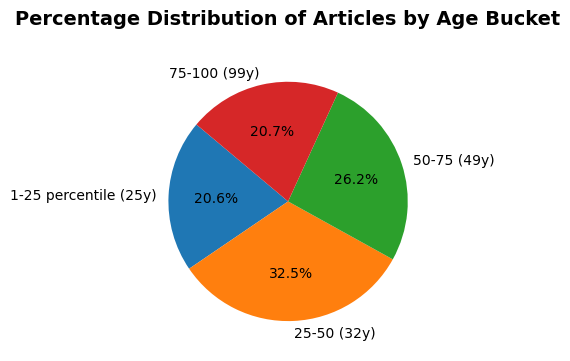

In [76]:
per_age = df3.groupby([ 'age_bracket']).agg({'article_id': 'count'}).reset_index()
plt.figure(figsize= (5,5))
plt.pie(per_age['article_id'],
        labels = per_age['age_bracket'],
        autopct='%1.1f%%',          # Shows the percentage numbers on the slices
        startangle=140,             # Rotates the start for a cleaner look
        colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']) # Clean corporate colors

plt.title('Percentage Distribution of Articles by Age Bucket', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [79]:
# grouping per active customers per age bracket
df_grouped = df3.groupby(['bucket', 'age_bracket']).agg({'article_id': 'count'})

# Checking contributions
df_grouped['contribution_%'] = (df_grouped['article_id'] / df_grouped.groupby(level='bucket')['article_id'].transform('sum')) * 100
df_grouped

/var/folders/0q/h_h23__s6kzbxw_96cqr6mw40000gn/T/ipykernel_8723/1646096237.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df3.groupby(['bucket', 'age_bracket']).agg({'article_id': 'count'})
/var/folders/0q/h_h23__s6kzbxw_96cqr6mw40000gn/T/ipykernel_8723/1646096237.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped['contribution_%'] = (df_grouped['article_id'] / df_grouped.groupby(level='bucket')['article_id'].transform('sum')) * 100


article_id  contribution_%
bucket                age_bracket                                      
1-25 percentile (50d) 1-25 percentile (25y)     3432211       20.447557
                      25-50 (32y)               5584426       33.269478
                      50-75 (49y)               4338279       25.845499
                      75-100 (99y)              3430517       20.437465
25-50 (150d)          1-25 percentile (25y)     1904351       22.309670
                      25-50 (32y)               2781261       32.582762
                      50-75 (49y)               2159625       25.300232
                      75-100 (99y)              1690752       19.807336
50-75 (400d)          1-25 percentile (25y)      831561       19.471350
                      25-50 (32y)               1353029       31.681742
                      50-75 (49y)               1108464       25.955150
                      75-100 (99y)               977636       22.891758
75-100 (740d)         1-25 percentile (25y)      356928       17.360700
                      25-50 (32y)                551934       26.845640
                      50-75 (49y)                685146       33.324967
                      75-100 (99y)               461946       22.468693

## insights
1) 18-25 years age group (top 25 percentile of age) contribute 20% sales
2) 25-32 years age group (25-50 percentile of age) contributes most, around 32% sales
3) 32-49 years age group (50-75 percentile of age) contributes 26% 
4) 49-99 years 20%
##### Around 60% coming from 25-49 years age group

### Per sales channel

In [82]:
df3.groupby('sales_channel_id').agg({'article_id':'count'})

,article_id
sales_channel_id,
1,9408462
2,22379862


###
--> sales channel id 2 dominates (70%)

### Repurchase behaviour

In [84]:
# How often is a (customer, article) pair bought more than once?
pair_counts = df3.groupby(['customer_id', 'article_id']).size()

# A "repurchase" = any pair bought 2+ times
repurchased_pairs = (pair_counts > 1).sum()
total_pairs = len(pair_counts)

print(f"Customer-article pairs bought more than once: {repurchased_pairs:,} of {total_pairs:,}")
print(f"Share of pairs that are repurchases: {repurchased_pairs / total_pairs:.1%}")

Customer-article pairs bought more than once: 3,515,413 of 27,306,439
Share of pairs that are repurchases: 12.9%


In [85]:
# What fraction of each customer's purchases are repeats of something they already bought?
# i.e. how "repurchase-driven" is the average customer?

# total transactions per customer
txns_per_customer = df3.groupby('customer_id').size()

# distinct articles per customer
distinct_articles_per_customer = df3.groupby('customer_id')['article_id'].nunique()

# repeats = total buys minus distinct items
repeat_buys = txns_per_customer - distinct_articles_per_customer

repeat_rate = repeat_buys.sum() / txns_per_customer.sum()
print(f"Share of all transactions that are repeat purchases: {repeat_rate:.1%}")

Share of all transactions that are repeat purchases: 14.1%


##
1) 14% sales form repeat purchases
2) 13% of customer product relationships were repurchases

next step is to look into customer product categories relationships


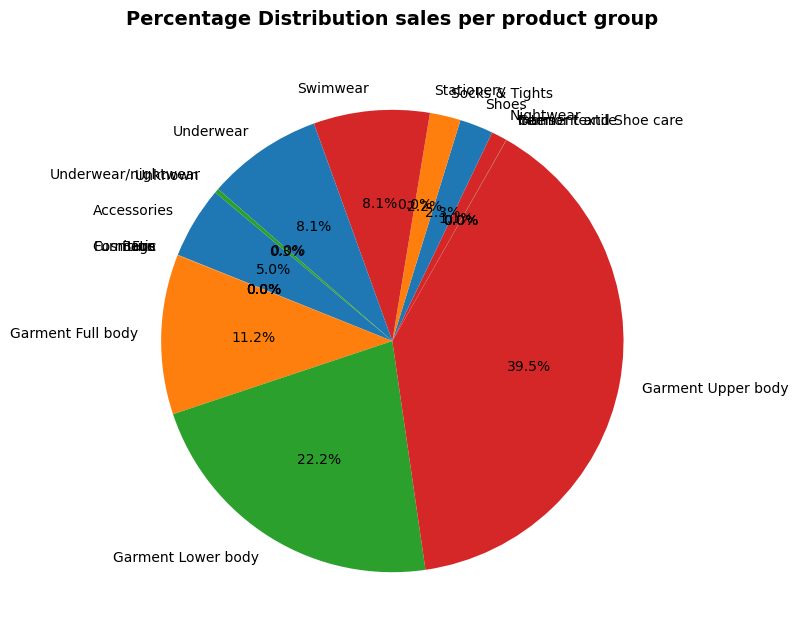

In [91]:
pg = df3.groupby(['product_group_name']).agg({'article_id':'count'}).reset_index()
plt.figure(figsize= (8,8))
plt.pie(pg['article_id'],
        labels = pg['product_group_name'],
        autopct='%1.1f%%',          # Shows the percentage numbers on the slices
        startangle=140,             # Rotates the start for a cleaner look
        colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']) # Clean corporate colors

plt.title('Percentage Distribution sales per product group', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [ ]:
# contribution table
pg['contri'] = (pg['article_id']/pg.article_id.sum())*100
pg.sort_values(by = 'article_id',ascending = False)

,product_group_name,article_id,contri
7,Garment Upper body,12552755,39.488571
6,Garment Lower body,7046054,22.165541
5,Garment Full body,3552470,11.175393
15,Swimwear,2579222,8.113740
16,Underwear,2565858,8.071700
0,Accessories,1599593,5.032014
12,Shoes,745521,2.345267
13,Socks & Tights,685712,2.157119
11,Nightwear,348180,1.095308
18,Unknown,97040,0.305269


###
1) Top 6 form around 90% of sales
2) Garment upper, garment lower, garment full, swimwear, underwear, Accessories form 90%

In [95]:
df3.columns

Index(['t_dat', 'customer_id', 'article_id', 'price', 'sales_channel_id', 'FN',
       'Active', 'club_member_status', 'fashion_news_frequency', 'age',
       'postal_code', 'product_code', 'prod_name', 'product_type_no',
       'product_type_name', 'product_group_name', 'graphical_appearance_no',
       'graphical_appearance_name', 'colour_group_code', 'colour_group_name',
       'perceived_colour_value_id', 'perceived_colour_value_name',
       'perceived_colour_master_id', 'perceived_colour_master_name',
       'department_no', 'department_name', 'index_code', 'index_name',
       'index_group_no', 'index_group_name', 'section_no', 'section_name',
       'garment_group_no', 'garment_group_name', 'detail_desc',
       'latest_sale_to_cut_off_date', 'bucket', 'age_bracket'],
      dtype='object')

## index group name

In [100]:
df3.index_group_name.unique()

array(['Ladieswear', 'Divided', 'Menswear', 'Baby/Children', 'Sport'],
      dtype=object)

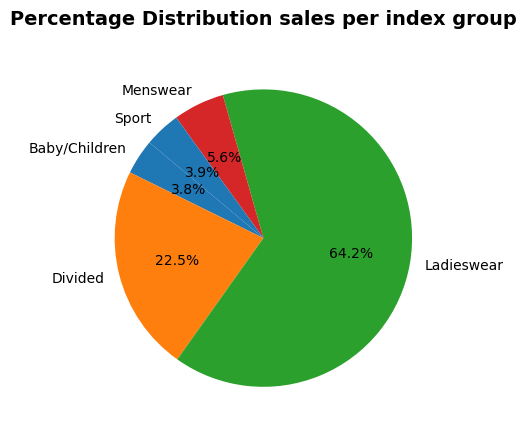

In [102]:
ig = df3.groupby(['index_group_name']).agg({'article_id':'count'}).reset_index()
plt.figure(figsize= (5,5))
plt.pie(ig['article_id'],
        labels = ig['index_group_name'],
        autopct='%1.1f%%',          # Shows the percentage numbers on the slices
        startangle=140,             # Rotates the start for a cleaner look
        colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']) # Clean corporate colors

plt.title('Percentage Distribution sales per index group', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [105]:
# per time bucket per index group
igg = df3.groupby(['bucket','index_group_name']).agg({'article_id':'count'})
igg['contribution_%'] = (igg['article_id'] / igg.groupby(level='bucket')['article_id'].transform('sum')) * 100
igg

/var/folders/0q/h_h23__s6kzbxw_96cqr6mw40000gn/T/ipykernel_8723/3386992689.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  igg = df3.groupby(['bucket','index_group_name']).agg({'article_id':'count'})
/var/folders/0q/h_h23__s6kzbxw_96cqr6mw40000gn/T/ipykernel_8723/3386992689.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  igg['contribution_%'] = (igg['article_id'] / igg.groupby(level='bucket')['article_id'].transform('sum')) * 100


article_id  contribution_%
bucket                index_group_name                            
1-25 percentile (50d) Baby/Children         541205        3.216131
                      Divided              3742246       22.238435
                      Ladieswear          10958001       65.118325
                      Menswear              930864        5.531694
                      Sport                 655514        3.895416
25-50 (150d)          Baby/Children         261039        3.045359
                      Divided              1947913       22.724932
                      Ladieswear           5552930       64.782132
                      Menswear              476426        5.558127
                      Sport                 333392        3.889450
50-75 (400d)          Baby/Children         135196        3.143566
                      Divided              1025368       23.841770
                      Ladieswear           2730612       63.491959
                      Menswear              227984        5.301065
                      Sport                 181561        4.221641
75-100 (740d)         Baby/Children         279909       13.405135
                      Divided               422727       20.244838
                      Ladieswear           1173717       56.210535
                      Menswear              135779        6.502598
                      Sport                  75941        3.636894

In [119]:

cust_index_share = df3.groupby('customer_id')['index_group_name'].apply(
    lambda x: x.value_counts(normalize=True).max()
)
print(f"Median customer makes {cust_index_share.median():.0%} of purchases in their top index group")
print(cust_index_share.describe())

Median customer makes 78% of purchases in their top index group
count    1.362281e+06
mean     7.761973e-01
std      1.965857e-01
min      2.000000e-01
25%      6.075949e-01
50%      7.777778e-01
75%      1.000000e+00
max      1.000000e+00
Name: index_group_name, dtype: float64


# 
1) Ladies wear and divided are the main categories with 86% sales
2) The distribution in all 'last sales from cut off' buckets is similar
3) Median customer based on number of items bought, makes 78% of their purchases from the same index group

## perceived color

In [114]:
df3.perceived_colour_value_name.unique()

array(['Dark', 'Dusty Light', 'Medium Dusty', 'Medium', 'Bright', 'Light',
       'Undefined', 'Unknown'], dtype=object)

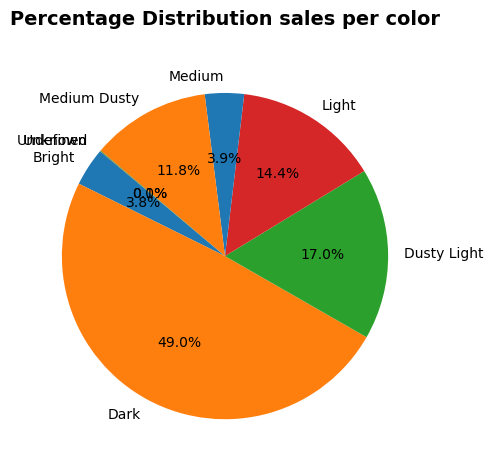

In [116]:
color = df3.groupby(['perceived_colour_value_name']).agg({'article_id':'count'}).reset_index()
plt.figure(figsize= (5,5))
plt.pie(color['article_id'],
        labels = color['perceived_colour_value_name'],
        autopct='%1.1f%%',          # Shows the percentage numbers on the slices
        startangle=140,             # Rotates the start for a cleaner look
        colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']) # Clean corporate colors

plt.title('Percentage Distribution sales per color', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [118]:
df_customers.columns

Index(['customer_id', 'FN', 'Active', 'club_member_status',
       'fashion_news_frequency', 'age', 'postal_code'],
      dtype='object')

## checking activity

In [120]:
# Purchases per customer, joined to their engagement attributes
cust = df3.groupby('customer_id').agg(
    n_purchases=('article_id', 'size'),
    fn=('FN', 'first'),
    active=('Active', 'first'),
    news=('fashion_news_frequency', 'first'),
).reset_index()

# Average purchases by fashion news frequency
print(cust.groupby('news')['n_purchases'].agg(['mean', 'median', 'count']))
print()
print(cust.groupby('active')['n_purchases'].agg(['mean', 'median', 'count']))

                mean  median   count
news                                
Monthly    12.282143     7.0     840
NONE       20.685726     8.0  871598
Regularly  28.715539    13.0  473843

            mean  median   count
active                          
1.0     29.02123    13.0  460899


## insight
--> Engaged customers (regular/active subscribers, ~470k) buy ~1.6x more than non-engaged; useful as a cold-start activity-likelihood feature. 'Monthly' bucket negligible (n=840). 'Active' is effectively binary — unsubscribed customers are missing, not zero.

## Final EDA Summary & Design Implications

This section consolidates the findings above and maps each to a concrete decision for the recommender.

### 1. Recency dominates sales
Customers active in the last ~50 days (top 25th percentile) drive ~52% of sales; contribution falls steadily for less-recent buckets.
**Design:** baseline recommendations use **recent** bestsellers (short trailing window), not all-time. Personalization effort concentrates on recently-active customers; dormant ones default to the recency fallback.

### 2. Womenswear dominates and customers are segment-loyal
Ladieswear + Divided ≈ 86% of sales. Median customer makes **78%** of purchases within a single index group (25%+ are entirely single-segment), and this concentration is consistent across all recency buckets.
**Design:** a **global** recency bestseller list is correct for the womenswear majority. Add a **segment-aware fallback** for the menswear / baby-children / sport minority, who are tightly concentrated in their own segment.

### 3. Sales concentrate in a few garment groups
Top 6 product groups (Garment Upper/Lower/Full body, Swimwear, Underwear, Accessories) ≈ 90% of sales.
**Design:** focus candidate generation on dominant groups; the long tail is negligible for scoring.

### 4. Repurchase is a minor signal
~14% of transactions are repeat purchases; ~13% of customer-article relationships repeat — expected for fast fashion.
**Design:** include "customer's recent purchases" as a **minor candidate source**, not a core driver.

### 5. Age is a mild signal
Roughly even spread; ~60% of sales from the 25–49 band, no extreme skew.
**Design:** **cold-start only** — age-bracket fallback for customers with no history. *(Note: 49–99 bracket likely contains placeholder ages — flag for cleaning.)*

### 6. Engagement is a tier-2 activity signal
Regular/active subscribers (~470k) buy ~1.6x more than non-engaged (median 13 vs 8). "Active" is effectively binary (unsubscribed = missing, not 0); "Monthly" bucket negligible (n=840).
**Design:** **cold-start likelihood** — flag engaged-but-thin-history customers as more likely to buy in the prediction window.

### 7. Channel concentration
Sales channel 2 ≈ 70% of transactions.
**Design:** channel as a ranking feature (confirm online vs in-store labelling before interpreting).

---

## Resulting Recommender Architecture

- **Validation:** time-based split — hold out final 7 days, predict from prior data only, score with MAP@12.
- **Backbone:** recent bestsellers + customer's own recent purchases.
- **Cold-start tiers:** active history → personalized; thin history → personal + segment/age fallback; no history → recent bestsellers (segment-aware where segment is known).
- **Main ranker:** candidate generation + LightGBM (not a neural net).
- **Refinement:** image-embedding visual similarity, added last.